In [1]:
import pandas as pd
import numpy as np
import time
import torch
import models
from demo import get_prediction

/home/amutua/inverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
the_model = models.GNNModel().to(device)
model_path = "models/GNN_Model.pth"
the_model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 32 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


The predicted band gap: 0.7037895917892456	 The actual band gap: 0.9927500000000008


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 24 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 23 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


The predicted band gap: 0.28388816118240356	 The actual band gap: 0.71875
The predicted band gap: 0.8315315246582031	 The actual band gap: 0.5468499999999992
The predicted band gap: 0.7880992889404297	 The actual band gap: 0.7783999999999978


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 48 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 47 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


The predicted band gap: 0.2263714224100113	 The actual band gap: 0.153500000000001


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 46 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]


The predicted band gap: 0.10054324567317963	 The actual band gap: 0.0235999999999947
The predicted band gap: 1.8099234104156494	 The actual band gap: 1.8096000000000032
The predicted band gap: 1.8392024040222168	 The actual band gap: 1.8297000000000023
Average prediction time: 1.5377779726404697


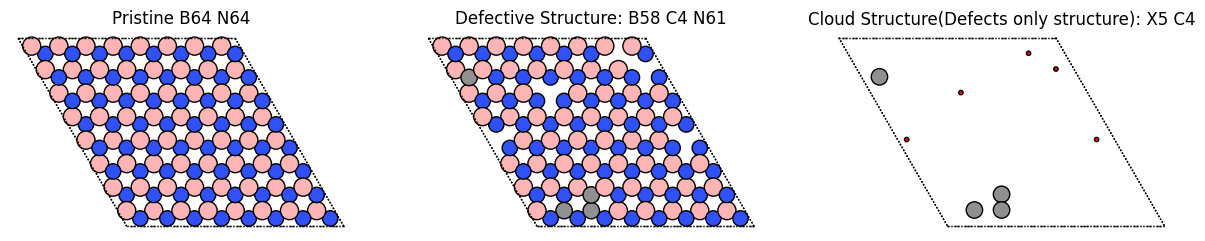

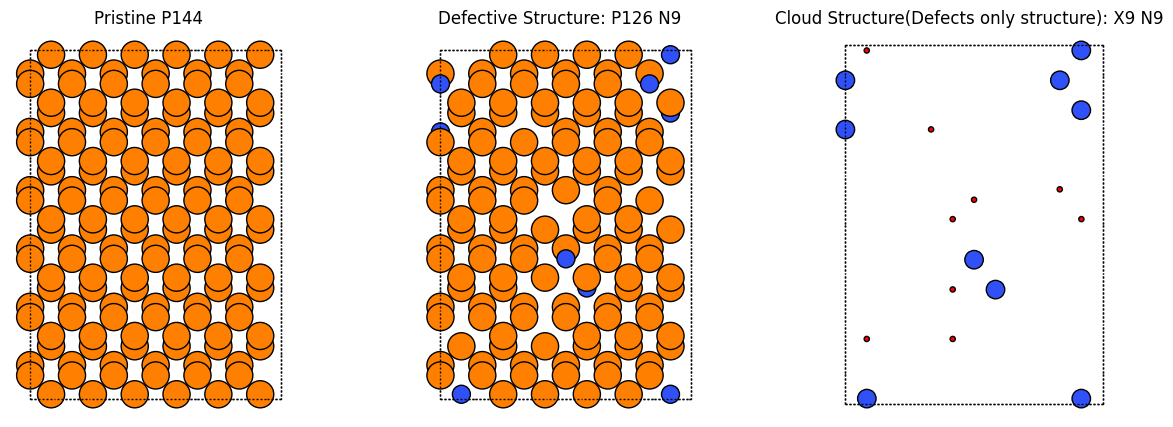

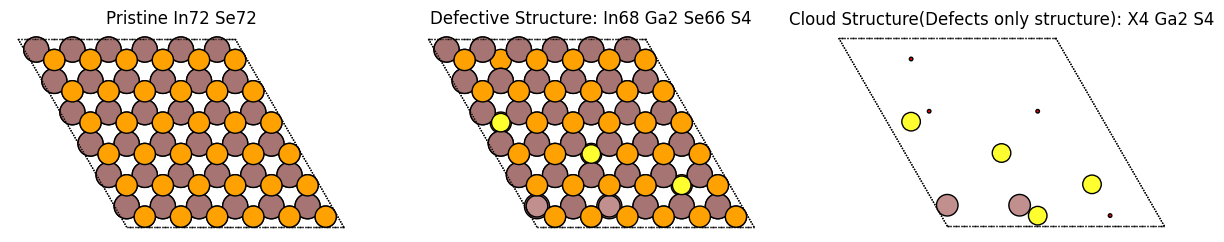

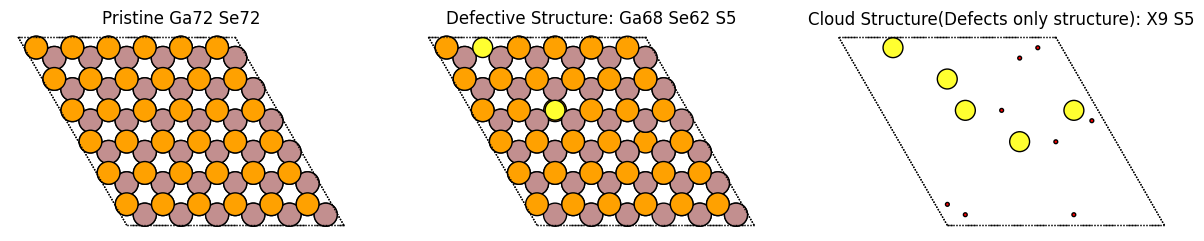

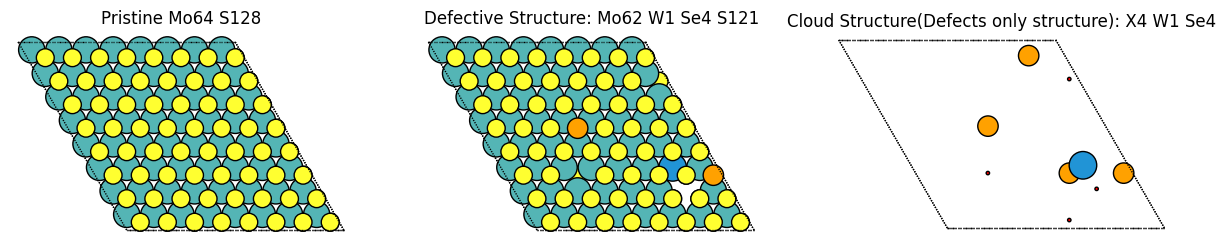

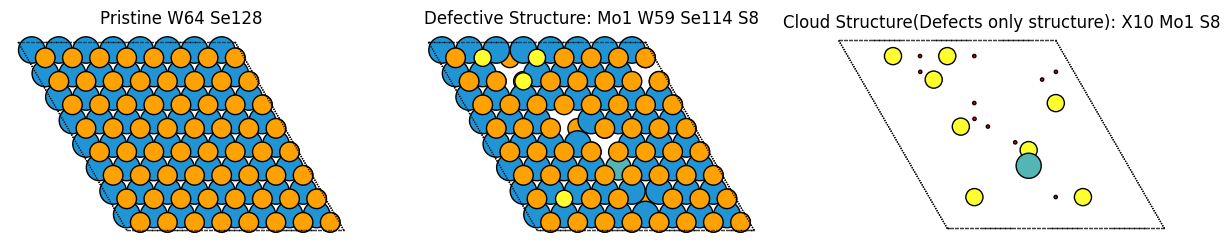

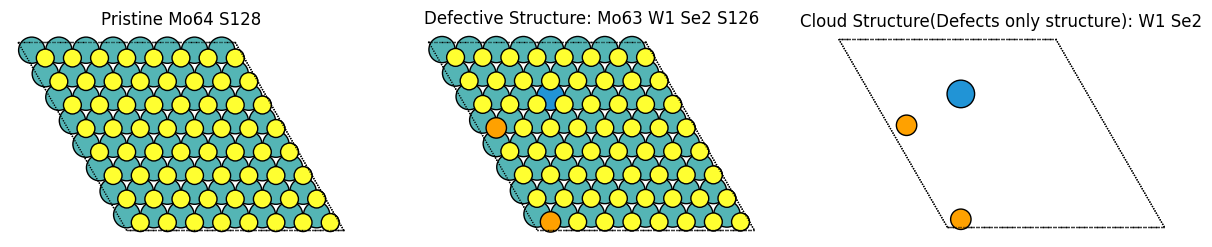

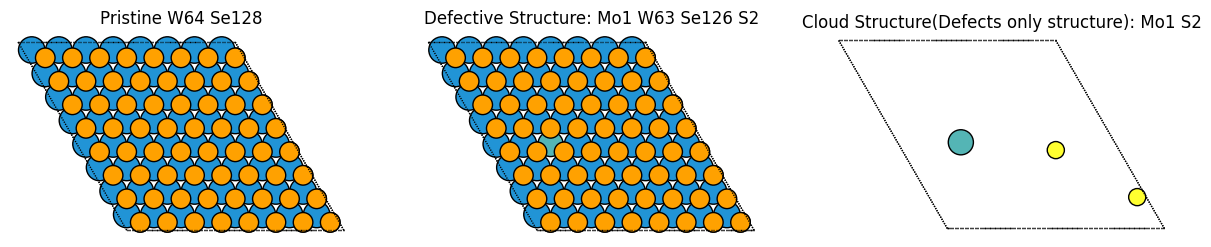

In [3]:
# Lets predict from all the materials
materials = ["high_BN", "high_P", "high_InSe", "high_GaSe", "high_MoS2", "high_WSe2", "low_MoS2", "low_WSe2"]
comb_df = pd.read_csv("combined/combined_data.csv")

sample_rows = []
for material in materials:
    sample_df = comb_df[comb_df['dataset_material'] == material]
    sample_row = sample_df.iloc[np.random.randint(0, len(sample_df))]
    sample_rows.append(sample_row)

time_taken = []

for row in sample_rows:
    defective_id = row['_id']
    pristine_material = row['dataset_material']
    target_bgv = row['band_gap_value']

    defective_cif_path = f"original_dataset/{pristine_material}/cifs/{defective_id}.cif"
    pristine_cif_path = f"ref_cifs/{pristine_material}.cif"
    start_time = time.perf_counter()
    print(get_prediction(defective_cif_path, pristine_cif_path, actual_value=target_bgv, vis=True))
    end_time = time.perf_counter()

    time_taken.append(end_time - start_time)

print(f"Average prediction time: {sum(time_taken)/len(sample_rows)}")  

In [ ]:
pristine_cif_path = 
defective_cif_path = 

print(get_prediction(defective_cif_path, pristine_cif_path, vis=True))